In [4]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory


In [5]:
import pandas as pd
pd.set_option('display.max_colwidth', None)
import re
from sklearn.model_selection import train_test_split

In [6]:
df=pd.read_csv('/content/train-balanced-sarcasm.csv')
print(df.shape)
df.sample(7)

(1010826, 10)


,label,comment,author,subreddit,score,ups,downs,date,created_utc,parent_comment
377057,1,"wow, look at this loser, not wanting people to touch her stuff",GideonJurassicPark,magicTCG,1,1,0,2016-04,2016-04-05 17:18:23,"I agree that it probably would have helped if I had said something to him at the time, I just didn't want to be seen as some person getting overly sensitive about someone touching her cards."
186949,0,I believe it happened with Flying witch 11 and 12 though,Mage_of_Shadows,anime,1,1,0,2016-06,2016-06-28 02:08:28,I'm sure AutoMod is immune from that.
132663,0,Did you also cancel your first order because you missed where you could change it to expedited shipping?,fdf06,GooglePixel,1,-1,-1,2016-10,2016-10-06 02:54:34,"Slightly off topic, but did they already put a charge on your card? I have two pending $700 charges (one for the actual order, one for an order I cancelled). I thought they don't charge the card until after it ships (which it obviously hasn't)?"
917979,1,So the pope was a french revolutionary ?,Quarkism,badhistory,2,2,0,2013-06,2013-06-21 13:02:28,"""Christianism"" isn't compatible with Liberalism, either, Don'tcha know."
1009735,0,Back in my day Pluto was a planet.,Digg4Died,Minecraft,30,30,0,2011-04,2011-04-12 02:41:35,Back in my day you could not save your worlds
247488,1,It's always sad to see millionaires have to file insurance claims and complain to the local council why they aren't getting money spent on their problems insted of spending money on the poor masses needs.,drfoxxx,worldnews,10,10,0,2016-06,2016-06-07 07:26:56,Collaroy Beach 'loses 50m' after Australia storm
769063,1,I love feminism from the 80's it is the best.,ckiemnstr345,OneY,9,9,0,2015-04,2015-04-09 14:18:48,"I got feminism from my mother in the 80s, not the internet recently."


In [7]:
df.comment.iloc[564385]

'When they add the VFX it looks about the same.'

In [8]:
df.label.value_counts()

,count
label,
0,505413
1,505413


In [9]:
df.shape

(1010826, 10)

## Selecting 120000 rows

In [10]:
df1=df[df['label']==1].sample(n=60000,random_state=42)
df0=df[df['label']==0].sample(n=60000,random_state=42)
df=pd.concat([df0,df1]).reset_index(drop=True)
df=df[['comment','label']]
print(df.shape)


(120000, 2)


In [11]:
from sklearn.utils import shuffle

df = shuffle(df, random_state=42).reset_index(drop=True)

In [12]:
df.sample(10)

,comment,label
6828,Yeah because that's what I was insinuating.,1
63303,"I think it means more like ""SneakyDaddy""",1
88805,THAT'S ANTI-SEMETIC!,1
51873,"It's still ahead of it's time in many ways, television seems like it's only just catching up.",0
114408,i hope this is,1
8394,FUDding intensifies.,0
61395,Extra bonus: today moved us up 10 spots in Kenpom.,0
28449,"I dont know, but if there isnt you guys should get a divorce.",1
87001,"Yep, you don't exactly rake in the dough with a women's studies degree",0
72225,"Yeah, we should just trust all parents to teach their kids everything they really need to know, because of course they would never withhold information and their knowledge is assuredly completely unbiased and current, unlike *public school* teachers!",1


In [13]:
df.comment.iloc[107399]

'Maybe he doesn\'t want to "commit suicide"...'

In [14]:
df.label.value_counts()

,count
label,
1,60000
0,60000


In [15]:
df.isna().sum()

,0
comment,6
label,0


In [16]:
df = df.dropna(subset=['comment'])
df['comment'] = df['comment'].astype(str)



In [17]:
df.isna().sum()

,0
comment,0
label,0


In [18]:

def preprocess_text(text):

    text = text.lower()                          #  lowercase

    text = re.sub(r'[^a-z0-9\s!?.,\'"]', ' ', text)
    text = re.sub(r'([!?.,])', r' \1 ', text)    #  make punctuation separate tokens
    text = re.sub(r'\s+', ' ', text).strip()     # normalize whitespace
    return text

In [19]:
df['clean_comment']=df['comment'].apply(lambda x:preprocess_text(x))

In [20]:
df.sample(7)

,comment,label,clean_comment
100983,oh I didn't even know there was a perk that did that lol,0,oh i didn't even know there was a perk that did that lol
47923,lol reddit is such garbage,0,lol reddit is such garbage
33595,"Really, I'd like to be friends with you ~enessay",0,"really , i'd like to be friends with you enessay"
78344,Shit I guess I needed a,1,shit i guess i needed a
27071,Whomever wrote that has good handwriting,0,whomever wrote that has good handwriting
115123,"But it's talking about white people, it can't possibly be racist!",1,"but it's talking about white people , it can't possibly be racist !"
86675,Not anymore lol,0,not anymore lol


## train_test_split

In [21]:
X=df['clean_comment']
y=df['label']
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

## Downloading pretrained Bert and Tokenizer

In [22]:
%pip install -q --force-reinstall "transformers==4.46.3" "huggingface-hub<1.0" tf-keras

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.1/44.1 kB 2.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.6/40.6 kB 2.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.4/57.4 kB 4.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.4/46.4 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 84.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 35.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 67.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 221.7/221.7 kB 15.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.2/4.2 MB 97.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 85.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.0/130.0 kB 11.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 801.6/801.6 kB 45.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 

In [23]:
import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"

import tensorflow as tf
from transformers import TFDistilBertForSequenceClassification, DistilBertTokenizerFast
model=TFDistilBertForSequenceClassification.from_pretrained('distilbert-base-uncased')
tokenizer=DistilBertTokenizerFast.from_pretrained('distilbert-base-uncased')

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Some weights of the PyTorch model were not used when initializing the TF 2.0 model TFDistilBertForSequenceClassification: ['vocab_projector.bias', 'vocab_transform.weight', 'vocab_layer_norm.weight', 'vocab_layer_norm.bias', 'vocab_transform.bias']
- This IS expected if you are initializing TFDistilBertForSequenceClassification from a PyTorch model trained on another task or with another architecture (e.g. initializing a TFBertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing TFDistilBertForSequenceClassification from a PyTorch model that you expect to be exactly identical (e.g. initializing a TFBertForSequenceClassification model from a BertForSequenceClassification model).
Some weights or buffers of the TF 2.0 model TFDistilBertForSequenceClassification were not initialized from the PyTorch model and are newly initialized: ['pre_classifier.weight', 'pre_classifier.bias', 'classifier.weight', 'classifier.bias']
You should 

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

In [24]:
model.summary()

Model: "tf_distil_bert_for_sequence_classification"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 distilbert (TFDistilBertMa  multiple                  66362880  
 inLayer)                                                        
                                                                 
 pre_classifier (Dense)      multiple                  590592    
                                                                 
 classifier (Dense)          multiple                  1538      
                                                                 
 dropout_19 (Dropout)        multiple                  0 (unused)
                                                                 
Total params: 66955010 (255.41 MB)
Trainable params: 66955010 (255.41 MB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [25]:
text=['hi hello ji bro','hello how are you sir ji']
tokenizer(text,padding=True)

{'input_ids': [[101, 7632, 7592, 10147, 22953, 102, 0, 0], [101, 7592, 2129, 2024, 2017, 2909, 10147, 102]], 'attention_mask': [[1, 1, 1, 1, 1, 1, 0, 0], [1, 1, 1, 1, 1, 1, 1, 1]]}

## Tokenization and Encoding

In [26]:
max_len=max(len(text) for text in df['clean_comment'])
print(max_len)

19714


In [27]:
train_encoding=tokenizer(X_train.tolist(),padding=True,truncation=True,max_length=150)
test_encoding=tokenizer(X_test.tolist(),padding=True,truncation=True,max_length=150)


In [28]:
train_dataset=tf.data.Dataset.from_tensor_slices((dict(train_encoding),y_train))
test_dataset=tf.data.Dataset.from_tensor_slices((dict(test_encoding),y_test))

## fine tuning bert

In [29]:
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=5e-5),
             loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
             metrics=['accuracy'])

history=model.fit(
    train_dataset.shuffle(1000).batch(16),
    epochs=5,
    validation_data=test_dataset.batch(16)
)

Epoch 1/7
6000/6000 [==============================] - 1612s 263ms/step - loss: 0.5597 - accuracy: 0.7091 - val_loss: 0.5295 - val_accuracy: 0.7292
Epoch 2/7
6000/6000 [==============================] - 1580s 263ms/step - loss: 0.4519 - accuracy: 0.7884 - val_loss: 0.5663 - val_accuracy: 0.7284
Epoch 3/7
6000/6000 [==============================] - 1580s 263ms/step - loss: 0.3014 - accuracy: 0.8753 - val_loss: 0.6901 - val_accuracy: 0.7090
Epoch 4/7
6000/6000 [==============================] - 1574s 262ms/step - loss: 0.1870 - accuracy: 0.9280 - val_loss: 0.8090 - val_accuracy: 0.7135
Epoch 5/7
6000/6000 [==============================] - 1570s 262ms/step - loss: 0.1357 - accuracy: 0.9491 - val_loss: 1.0213 - val_accuracy: 0.7147
Epoch 6/7
6000/6000 [==============================] - 1572s 262ms/step - loss: 0.1066 - accuracy: 0.9611 - val_loss: 1.1798 - val_accuracy: 0.7006
Epoch 7/7
6000/6000 [==============================] - 1573s 262ms/step - loss: 0.0925 - accuracy: 0.9662 - val_

In [30]:
import matplotlib.pyplot as plt
import numpy as np

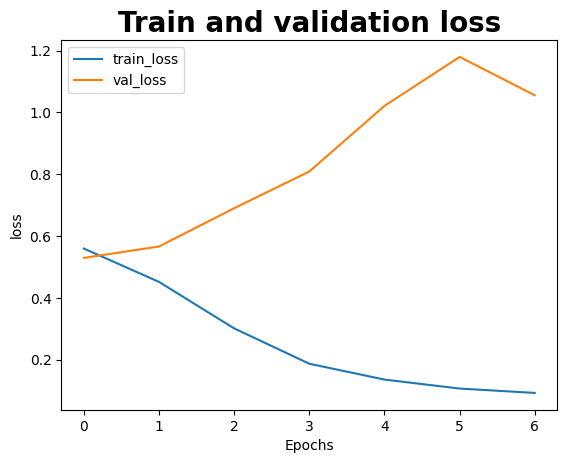

In [32]:
plt.plot(history.history['loss'],label='train_loss')
plt.plot(history.history['val_loss'],label='val_loss')
plt.title('Train and validation loss',fontweight='bold',fontsize=20)
plt.xlabel('Epochs')
plt.ylabel('loss')
plt.legend()

## metrics

In [34]:
from sklearn.metrics import classification_report,confusion_matrix

In [35]:
y_probabs=model.predict(test_dataset.batch(16))
y_pred=np.argmax(y_probabs.logits,axis=1)
cm=confusion_matrix(y_test,y_pred)

1500/1500 [==============================] - 127s 82ms/step


In [36]:
cm

array([[8621, 3405],
       [3632, 8341]])

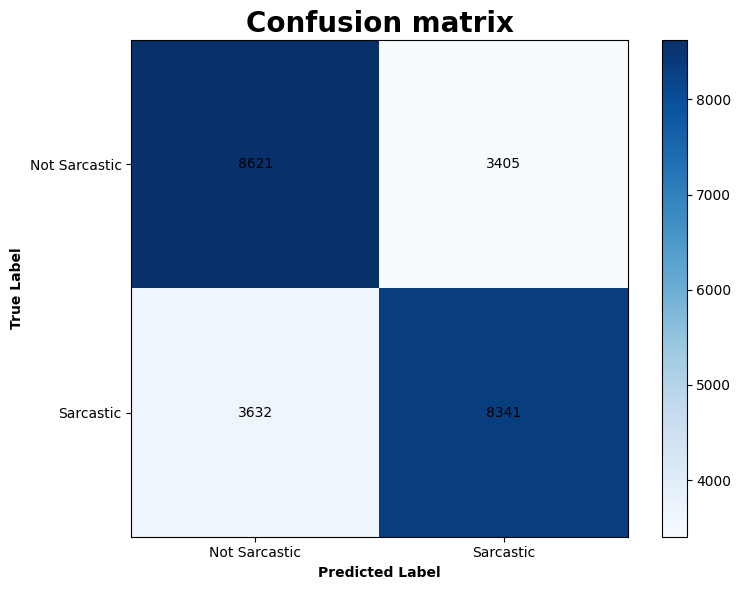

In [39]:
plt.figure(figsize=(8,6))
plt.imshow(cm,interpolation='nearest',cmap=plt.cm.Blues)
plt.title('Confusion matrix',fontweight='bold',fontsize=20,)
plt.colorbar()
tick_marks=np.arange(2)
plt.xticks(tick_marks,['Not Sarcastic','Sarcastic'])
plt.yticks(tick_marks,['Not Sarcastic','Sarcastic'])

thresh=cm.max()/2
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j,i,str(cm[i,j]),ha='center',va='center',color='black')
plt.xlabel('Predicted Label',fontweight='bold')
plt.ylabel('True Label',fontweight='bold')
plt.tight_layout()
plt.show()

In [40]:
report=classification_report(y_test,y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.70      0.72      0.71     12026
           1       0.71      0.70      0.70     11973

    accuracy                           0.71     23999
   macro avg       0.71      0.71      0.71     23999
weighted avg       0.71      0.71      0.71     23999



## save and load model

In [41]:
model.save_pretrained('my_distil_bert')

In [42]:
loaded_model=TFDistilBertForSequenceClassification.from_pretrained('my_distil_bert')

Some layers from the model checkpoint at my_distil_bert were not used when initializing TFDistilBertForSequenceClassification: ['dropout_19']
- This IS expected if you are initializing TFDistilBertForSequenceClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing TFDistilBertForSequenceClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
Some layers of TFDistilBertForSequenceClassification were not initialized from the model checkpoint at my_distil_bert and are newly initialized: ['dropout_39']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


# Prediction test

In [45]:
def predictive(text):
    text=preprocess_text(text)
    inputs=tokenizer(text,padding=True,truncation=True,max_length=150,return_tensors='tf')
    logits=loaded_model(inputs).logits
    probs=tf.nn.softmax(logits,axis=1).numpy()
    predicted_label=np.argmax(probs,axis=1)
    return predicted_label

In [50]:
text='i love it when certain people who will never , ever give birth tell women what they can do with their bodies'
predicted_label=predictive(text)
print('predicted label',predicted_label)

predicted label [1]


In [ ]:
#preprocess_text('black people 🤗😒😓🙏😊🔥🙏  cant afford batteries @ f43$  ?')

In [49]:
df.iloc[5]

,5
comment,"I love it when certain people who will never, ever give birth tell women what they can do with their bodies."
label,1
clean_comment,"i love it when certain people who will never , ever give birth tell women what they can do with their bodies ."
